In [1]:
import torch 
from reasoning_from_scratch.ch02 import get_device 
from reasoning_from_scratch.ch03 import (
    load_model_and_tokenizer 
)

device = get_device()
# device = torch.device('cpu')

model, tokenizer = load_model_and_tokenizer(
    which_model = 'base',
    device = device,
    use_compile = False
)
print(device)

Using Apple Silicon GPU (MPS)
✓ qwen3/qwen3-0.6B-base.pth already up-to-date
mps


In [2]:
from reasoning_from_scratch.ch03 import render_prompt 
from reasoning_from_scratch.ch04 import (
    generate_text_stream_concat_flex,   
    generate_text_top_p_stream_cache
)

raw_prompt = (
    'Half the value of $3x-9$ is $x+37$. '
    'What is the value of $x$?'
)
prompt = render_prompt(raw_prompt)
prompt_cot = prompt + '\n\nExplain step by step.' 

torch.manual_seed(0)
response_1 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens = 2048, verbose = True,
    generate_func = generate_text_top_p_stream_cache,
    temperature = 0.9, top_p = 0.9
)

 ### Step 1: Understand the problem

The problem states that half the value of \(3x - 9\) is equal to \(x + 37\). We need to find the value of \(x\).

### Step 2: Translate the problem into an equation

Let's translate the given statement into an equation. Half of \(3x - 9\) is equal to \(x + 37\).

\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 3: Solve the equation

To solve for \(x\), we'll first eliminate the fraction by multiplying both sides of the equation by 2:

\[
2 \times \frac{1}{2}(3x - 9) = 2 \times (x + 37)
\]

This simplifies to:

\[
3x - 9 = 2x + 74
\]

### Step 4: Isolate the variable \(x\)

Now, we'll isolate \(x\) by subtracting \(2x\) from both sides of the equation:

\[
3x - 2x - 9 = 74
\]

Simplifying this, we get:

\[
x - 9 = 74
\]

### Step 5: Solve for \(x\)

Next, we'll add 9 to both sides to solve for \(x\):

\[
x - 9 + 9 = 74 + 9
\]

This simplifies to:

\[
x = 83
\]

### Step 6: Verify the solution

To ensure our solution is correct, we'll substitute \(x = 83

In [3]:
torch.manual_seed(3)
response_2 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens = 2048, verbose = True,
    generate_func = generate_text_top_p_stream_cache,
    temperature = 0.9, top_p = 0.9
)

 We start with the equation:

\[
\frac{1}{2} \times (3x - 9) = x + 37
\]

Step 1: Multiply both sides of the equation by 2 to eliminate the fraction:

\[
2 \times \frac{1}{2} \times (3x - 9) = 2 \times (x + 37)
\]

Simplifying both sides:

\[
3x - 9 = 2x + 74
\]

Step 2: Subtract \(2x\) from both sides to get all the \(x\) terms on one side:

\[
3x - 2x - 9 = 74
\]

Simplifying:

\[
x - 9 = 74
\]

Step 3: Add 9 to both sides to isolate \(x\):

\[
x - 9 + 9 = 74 + 9
\]

Simplifying:

\[
x = 83
\]

Final Answer:

\[
\boxed{83}
\]

In [4]:
print('response 1 characters:', len(response_1))
print('response 1 tokens:', len(tokenizer.encode(response_1)))
print('\nresponse 2 characters:', len(response_2))
print('response 2 tokens:', len(tokenizer.encode(response_2)))

response 1 characters: 1419
response 1 tokens: 534

response 2 characters: 533
response 2 tokens: 231


In [5]:
from reasoning_from_scratch.ch03 import extract_final_candidate 
import math 

def heuristic_score(
    answer, 
    prompt = None, 
    brevity_bonus = 500.0,
    boxed_bonus = 2.0,
    extract_bonus = 1.0,
    fulltext_bonus = 0.0
):
    score = 0.0
    
    cand = extract_final_candidate(answer, fallback = 'none') 
    if cand:
        score += boxed_bonus    # If a final candidate answer was successfully extracted, add the boxed_bonus to the score +2.0
    
    else:
        cand = extract_final_candidate(answer, fallback = 'number_only' )
        if cand:
            score += extract_bonus # If no boxed answer was found earlier, try to extract just a number from the answer 1.0
        else:
            cand = extract_final_candidate(
                answer, fallback = 'number_then_full'    # If no boxed answer was found earlier, try a number first,
                                                         # otherwise fall back to the full text 0.0
            )
            if cand:
                score += fulltext_bonus
            
    score += 1.5 * math.exp(-len(answer) / brevity_bonus)
    return score

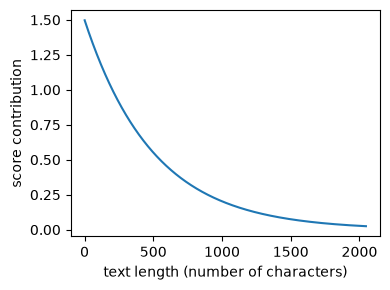

In [6]:
import matplotlib.pyplot as plt 

def plot_brevity_curve(brevity_bonus, max_len = 2048):
    lengths = torch.arange(1, max_len)
    scores = 1.5 * torch.exp(-lengths / brevity_bonus)
    
    plt.figure(figsize = (4, 3))
    plt.plot(lengths, scores)
    plt.xlabel('text length (number of characters)')
    plt.ylabel('score contribution')
    plt.tight_layout()
    plt.show()
    
plot_brevity_curve(500)

In [7]:
print(round(heuristic_score(response_1), 3))

2.088


In [8]:
print(round(heuristic_score(response_2), 3))

2.517


In [9]:
@torch.inference_mode()

def calc_next_token_probas(model, tokenizer, prompt, device, show = True):
    
    token_ids = torch.tensor(tokenizer.encode(prompt), device = device)
    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_probas = torch.softmax(logits, dim = -1)
    
    t_idx = torch.arange(0, token_ids.shape[0] -1, device = device)
    
    next_ids = token_ids[1:]
    next_token_probas = all_probas[t_idx, next_ids]
    
    prod_next_token_probas = torch.prod(next_token_probas)      # torch.prod() multiplies all values in a tensor together
    
    if show:
        print('next-token probabilities:', next_token_probas)
        print('joint probability:', prod_next_token_probas)
    else:
        return next_token_probas, prod_next_token_probas

In [10]:
torch.set_printoptions(precision = 4, sci_mode = True)
calc_next_token_probas(
    model, tokenizer, device = device, 
    prompt = 'The capital of Germany is berlin' 
)

next-token probabilities: tensor([5.7936e-05, 4.5117e-01, 1.6235e-02, 7.2656e-01, 4.0245e-04],
       device='mps:0', dtype=torch.bfloat16)
joint probability: tensor(1.2369e-10, device='mps:0', dtype=torch.bfloat16)


In [11]:
calc_next_token_probas(
    model, tokenizer, device = device,
    prompt = 'The capital of Germany is Bridge'
)

next-token probabilities: tensor([5.7936e-05, 4.5117e-01, 1.6235e-02, 7.2656e-01, 3.0361e-07],
       device='mps:0', dtype=torch.bfloat16)
joint probability: tensor(9.3703e-14, device='mps:0', dtype=torch.bfloat16)


In [12]:
torch.set_printoptions(precision = 4, sci_mode = False)
logits = torch.linspace(-2, 2, steps = 7)
probas = torch.softmax(logits, dim = -1)
print(probas)

tensor([0.0090, 0.0175, 0.0341, 0.0665, 0.1295, 0.2522, 0.4912])


In [13]:
print(torch.log(probas))

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


In [14]:
log_probas = torch.log_softmax(logits, dim=-1)              # # log + softmax in one function
print(log_probas)

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


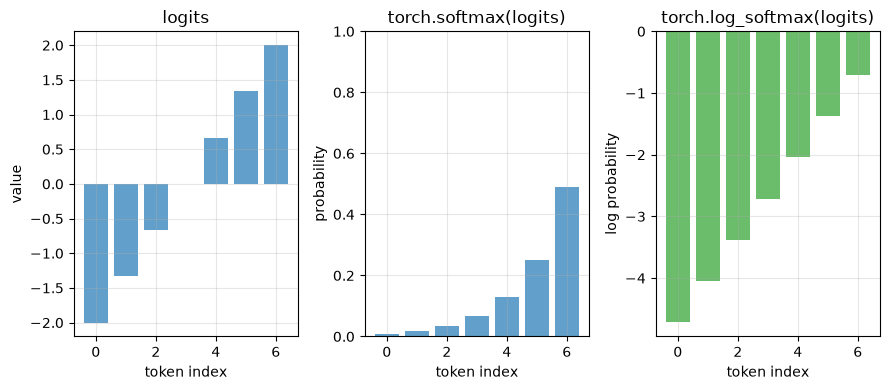

In [15]:
plt.figure(figsize = (9, 4))

plt.subplot(1, 3, 1)
plt.bar(range(len(logits)), logits, color = 'C0', alpha = 0.7)
plt.title('logits')
plt.xlabel('token index')
plt.ylabel('value')
plt.grid(alpha = 0.3)

plt.subplot(1, 3, 2)
plt.bar(range(len(probas)), probas, color = 'C0', alpha = 0.7)
plt.title('torch.softmax(logits)')
plt.xlabel('token index')
plt.ylabel('probability')

plt.ylim(0, 1)
plt.grid(alpha = 0.3)

plt.subplot(1, 3, 3)
plt.bar(range(len(log_probas)), log_probas, color = 'C2', alpha = 0.7)
plt.title('torch.log_softmax(logits)')
plt.xlabel('token index')
plt.ylabel('log probability')
plt.grid(alpha = 0.3)

plt.tight_layout()
plt.savefig('logits_softmax_log_softmax.pdf')
plt.show()

In [16]:
@torch.inference_mode()

def calc_next_token_logprobas(model, tokenizer, prompt, device, show = True):
    
    token_ids = torch.tensor(tokenizer.encode(prompt), device = device)
    
    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_logprobas = torch.log_softmax(logits, dim = -1)
    
    t_idx = torch.arange(0, token_ids.shape[0] -1, device = device)
    next_ids = token_ids[1:]
    next_token_logprobas = all_logprobas[t_idx, next_ids]
    
    sum_next_token_logprobas = torch.sum(next_token_logprobas)
    
    if show:
        print('next-token log-probabilities:', next_token_logprobas)
        print('joint log-proability:', sum_next_token_logprobas)
    else:
        return next_token_logprobas, sum_next_token_logprobas 

In [17]:
calc_next_token_logprobas(
    model, tokenizer, device = device,
    prompt = 'The calital of Germany is Berlin' 
)

next-token log-probabilities: tensor([-10.1250, -16.3750,  -4.6562,  -9.5000,  -1.5625, -10.0000],
       device='mps:0', dtype=torch.bfloat16)
joint log-proability: tensor(-52.2500, device='mps:0', dtype=torch.bfloat16)


In [18]:
calc_next_token_logprobas(
    model, tokenizer, device = device,
    prompt = 'The calital of Germany is Bridge' 
)

next-token log-probabilities: tensor([-10.1250, -16.3750,  -4.6562,  -9.5000,  -1.5625, -14.7500],
       device='mps:0', dtype=torch.bfloat16)
joint log-proability: tensor(-57., device='mps:0', dtype=torch.bfloat16)


In [21]:
example_prompt = 'What is the capital of Germany?' 
example_answer = ' The capital of Germany is Berlin.' 

next_token_logprobas, sum_next_token_logprobas = calc_next_token_logprobas(
    model, tokenizer, device = device,
    prompt = example_prompt + example_answer,
    show = False
)
print('next token logprobas:', next_token_logprobas)
print('joint log probability:', sum_next_token_logprobas)

next token logprobas: tensor([-0.4512, -0.3691, -8.1875, -0.4141, -3.7812, -3.0625, -1.1641, -0.0023,
        -0.0181, -0.0025, -0.0104, -0.0684, -0.1631], device='mps:0',
       dtype=torch.bfloat16)
joint log probability: tensor(-17.7500, device='mps:0', dtype=torch.bfloat16)


In [22]:
print(len(tokenizer.encode(example_answer)))

7


In [23]:
last_7 = next_token_logprobas[-7:]
print(last_7)
print(torch.mean(last_7))

tensor([-1.1641, -0.0023, -0.0181, -0.0025, -0.0104, -0.0684, -0.1631],
       device='mps:0', dtype=torch.bfloat16)
tensor(-0.2041, device='mps:0', dtype=torch.bfloat16)


In [24]:
@torch.inference_mode()

def avg_logprob_answer(model, tokenizer, prompt, answer, device = 'cpu'):
    
    prompt_ids = tokenizer.encode(prompt)
    answer_ids = tokenizer.encode(answer)
    full_ids = torch.tensor(prompt_ids + answer_ids, device = device)
    
    logits = model(full_ids.unsqueeze(0)).squeeze(0)
    logprobs = torch.log_softmax(logits, dim = -1)
    
    start = len(prompt_ids) -1
    end = full_ids.shape[0] - 1
    
    t_idx = torch.arange(start, end, device = device)
    next_tokens = full_ids[start + 1 : end + 1]
    next_token_logps = logprobs[t_idx, next_tokens]
    
    return torch.mean(next_token_logps)

In [25]:
score_1 = avg_logprob_answer(
    model, tokenizer, 
    prompt = 'What is the capital of Germany?',
    answer =  ' The capital of Germany is Berlin.',
    device = device 
)
print(score_1)

tensor(-0.2041, device='mps:0', dtype=torch.bfloat16)


In [26]:
score_2 = avg_logprob_answer(
    model, tokenizer,
    prompt = 'What is the capital of Germany?',
    answer = ' The capital of Germany is Bridge.',
    device = device
)
print(score_2)

tensor(-3.8594, device='mps:0', dtype=torch.bfloat16)
